# QSV2G — Independent Quantum QSS Validation (Kaggle)

This smaller notebook isolates the **mathematical three-qutrit `(2,3)` QSS** construction used in Section IV of `QSV2G_main8_SectionIV_Revised.tex`. CPU is sufficient.

1. On Kaggle enable **Internet** (only needed to install Qiskit/PennyLane), then **Run All**.
2. Compare NumPy exact 27-amplitude qutrit states with optional **6-qubit embeddings** in Qiskit and PennyLane.
3. Test all three authorized pairs, one-share secrecy and stabilizer relations, then apply a specified qutrit-X error model.
4. Download `qsv2g_quantum_results.zip` from Kaggle Output.

**Limitations:** This is a simulated classical-secret QSS scheme in entangled qutrit states, not a formal malicious-secure verifiable-QSS protocol; optional 6-qubit embeddings are not physical qutrit devices.

## Dependencies

In [1]:
import os, sys, subprocess, importlib.util
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import sqrt
IN_KAGGLE=os.path.exists('/kaggle/working')
if IN_KAGGLE:
    req=[pkg for name,pkg in [('qiskit','qiskit>=1.0'),('pennylane','pennylane>=0.40')] if importlib.util.find_spec(name) is None]
    if req: subprocess.run([sys.executable,'-m','pip','install','--quiet',*req],check=True)
OUT=Path('/kaggle/working/qsv2g_quantum' if IN_KAGGLE else '/mnt/data/qsv2g_quantum_results')
OUT.mkdir(parents=True,exist_ok=True)
SLOT={'A':0,'B':1,'C':2}
class ProtocolAbort(Exception): pass
def require(cond,msg):
    if not cond: raise ProtocolAbort(msg)


## Exact Bell and qutrit mathematical functions

In [2]:
# ---- Quantum statevectors ----
I2=np.eye(2,dtype=np.complex128)
X2=np.array([[0,1],[1,0]],complex)
Z2=np.diag([1,-1]).astype(complex)
H2=np.array([[1,1],[1,-1]],complex)/np.sqrt(2)
CNOT=np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]],complex)
BELL=np.array([1,0,0,1],complex)/np.sqrt(2)

def dense_encode_decode(two_bits):
    a,b=two_bits
    state=np.kron(np.linalg.matrix_power(Z2,a)@np.linalg.matrix_power(X2,b),I2)@BELL
    final=np.kron(H2,I2)@CNOT@state
    probabilities=np.abs(final)**2
    idx=int(np.argmax(probabilities))
    require(np.isclose(probabilities[idx],1,atol=1e-12),'Bell decoding failure')
    return (idx//2,idx%2)

def dense_transport_tag(tag):
    recovered=bytearray()
    bits=''.join(f'{byte:08b}' for byte in tag)
    out=''
    for k in range(0,len(bits),2):
        aa,bb=dense_encode_decode((int(bits[k]),int(bits[k+1])))
        out+=str(aa)+str(bb)
    recovered.extend(int(out[j:j+8],2) for j in range(0,len(out),8))
    return bytes(recovered)

OMEGA=np.exp(2j*np.pi/3)
X3=np.roll(np.eye(3,dtype=complex),1,axis=0)
Z3=np.diag([OMEGA**j for j in range(3)])


def qss_state(s):
    """|psi(s)> = sum_r |r,r+s,r+2s> /sqrt(3)."""
    require(s in (0,1,2),'Invalid trit')
    state=np.zeros((3,3,3),dtype=complex)
    for r in range(3): state[r,(r+s)%3,(r+2*s)%3]=1/np.sqrt(3)
    return state

def reduced_density(psi, kept):
    moved=np.moveaxis(psi,kept,0).reshape(3,-1)
    return moved@moved.conj().T

def measure_pair(psi, pair, rng, x_fault=False):
    """Sample joint computational measurement of two shares from a 3-qutrit statevector.
    x_fault applies a qutrit-X error to the SECOND selected share before measuring.
    """
    u,v=[SLOT[p] for p in pair]
    state=np.moveaxis(psi,(u,v),(0,1))
    probs=(np.abs(state)**2).sum(axis=2).reshape(-1)
    idx=int(rng.choice(9,p=probs/probs.sum()))
    xu,xv=divmod(idx,3)
    if x_fault: xv=(xv+1)%3
    return xu,xv

def recover_symbol(pair,xu,xv):
    denom=(SLOT[pair[1]]-SLOT[pair[0]])%3
    return ((xv-xu)*pow(denom,-1,3))%3

def qss_consistency():
    Xa=np.kron(np.kron(X3,X3),X3)
    Za=np.kron(np.kron(Z3,Z3),Z3)
    vals=[]
    for s in range(3):
        psi=qss_state(s)
        psi_flat=psi.reshape(-1)
        vals.append({
            's':s,
            'norm':float(np.vdot(psi_flat,psi_flat).real),
            'x_stabilizer_error':float(np.linalg.norm(Xa@psi_flat-psi_flat)),
            'z_stabilizer_error':float(np.linalg.norm(Za@psi_flat-psi_flat)),
            'one_share_distances':[float(np.linalg.norm(reduced_density(psi,b)-np.eye(3)/3)) for b in range(3)],
        })
    return vals



## Density-matrix and stabilizer correctness

In [3]:
# Build all three 27D states and test normalization, stabilizers, and individual shares.
qc=qss_consistency()
for x in qc:
    assert abs(x['norm']-1)<1e-12
    assert x['x_stabilizer_error']<1e-10 and x['z_stabilizer_error']<1e-10
    assert max(x['one_share_distances'])<1e-10
pd.DataFrame(qc).to_csv(OUT/'quantum_state_checks.csv',index=False)
display(pd.DataFrame(qc))
print('All three encoded states passed: norm, X/Z stabilizers and per-share maximally mixed tests.')


,s,norm,x_stabilizer_error,z_stabilizer_error,one_share_distances
0,0,1.0,0.0,8.100577e-16,"[1.9229626863835638e-16, 1.9229626863835638e-1..."
1,1,1.0,0.0,6.600967e-16,"[1.9229626863835638e-16, 1.9229626863835638e-1..."
2,2,1.0,0.0,6.553555e-16,"[1.9229626863835638e-16, 1.9229626863835638e-1..."


All three encoded states passed: norm, X/Z stabilizers and per-share maximally mixed tests.


## Three authorized pairs

In [4]:
# Every secret symbol (0,1,2), every authorized pair (AB, AC, BC).
pairs=[('A','B'),('A','C'),('B','C')]
rng=np.random.default_rng(20261022)
rows=[]
for s in range(3):
 for pair in pairs:
  x=sum(recover_symbol(pair,*measure_pair(qss_state(s),pair,rng))==s for _ in range(500))
  rows.append({'symbol':s,'pair':''.join(pair),'shots':500,'correct':x,'success_rate':x/500})
res=pd.DataFrame(rows)
assert res.success_rate.eq(1).all()
display(res)
res.to_csv(OUT/'ideal_qss_pair_reconstruction.csv',index=False)


,symbol,pair,shots,correct,success_rate
0,0,AB,500,500,1.0
1,0,AC,500,500,1.0
2,0,BC,500,500,1.0
3,1,AB,500,500,1.0
4,1,AC,500,500,1.0
5,1,BC,500,500,1.0
6,2,AB,500,500,1.0
7,2,AC,500,500,1.0
8,2,BC,500,500,1.0


## Qiskit and PennyLane 6-qubit subspace checks

In [5]:
# Encode three qutrits as six qubits: 0->|00>, 1->|01>, 2->|10>.
# Qiskit uses little-endian qubit indices, so index = a + 4*b + 16*c.
# PennyLane uses big-endian wire order, so reverse the qubit-level bit ordering.
s=1
vec_qiskit=np.zeros(64,complex)
for r in range(3):
  a,b,c=r,(r+s)%3,(r+2*s)%3
  vec_qiskit[a+4*b+16*c]=1/np.sqrt(3)
# Reverse all 6 bits to translate from Qiskit to PennyLane state ordering.
def reverse6(i): return int(f'{i:06b}'[::-1],2)
vec_pennylane=np.zeros(64,complex)
for i in range(64): vec_pennylane[reverse6(i)]=vec_qiskit[i]
assert np.isclose(np.linalg.norm(vec_qiskit),1)
try:
 from qiskit import QuantumCircuit
 from qiskit.quantum_info import Statevector
 c=QuantumCircuit(6); c.initialize(vec_qiskit,range(6))
 observed=Statevector.from_instruction(c).data
 assert np.allclose(observed,vec_qiskit,atol=1e-10)
 print('Qiskit embedded three-qutrit state, s=1: PASS')
except ImportError:
 print('Qiskit not installed locally; check will run on Kaggle after automatic install.')
try:
 import pennylane as qml
 dev=qml.device('default.qubit',wires=6)
 @qml.qnode(dev)
 def prepare():
    qml.StatePrep(vec_pennylane,wires=range(6))
    return qml.state()
 observed=prepare()
 assert np.allclose(observed,vec_pennylane,atol=1e-10)
 print('PennyLane embedded three-qutrit state, s=1: PASS')
except ImportError:
 print('PennyLane not installed locally; check will run on Kaggle after automatic install.')


Qiskit not installed locally; check will run on Kaggle after automatic install.
PennyLane not installed locally; check will run on Kaggle after automatic install.


## Controlled quantum X-channel error experiment

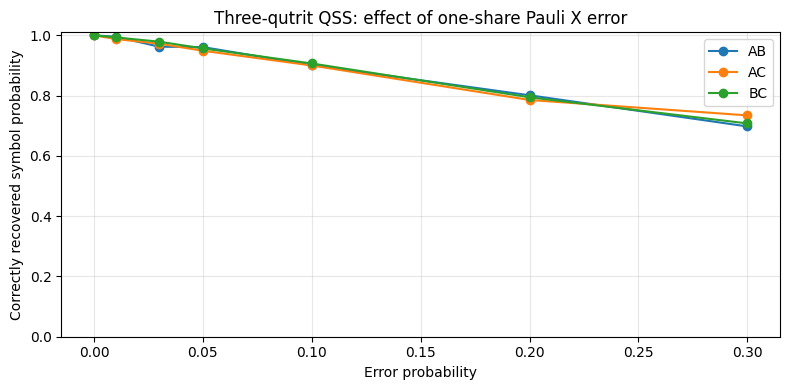

,pair,x_error_p,shots,successes,success_rate
0,AB,0.00,900,900,1.000000
1,AB,0.01,900,896,0.995556
2,AB,0.03,900,866,0.962222
3,AB,0.05,900,865,0.961111
4,AB,0.10,900,811,0.901111
5,AB,0.20,900,721,0.801111
6,AB,0.30,900,628,0.697778
7,AC,0.00,900,900,1.000000
8,AC,0.01,900,889,0.987778
9,AC,0.03,900,875,0.972222


In [6]:
# Qutrit X operator rotates an individual measured share by +1 modulo 3.
# This is a defined discrete Pauli-X error model, not arbitrary quantum network noise.
rates=[0.0,0.01,0.03,0.05,0.10,0.20,0.30]
rng=np.random.default_rng(705)
rows=[]; N=900
for pair in pairs:
 for rate in rates:
  good=0
  for _ in range(N):
   s=int(rng.integers(0,3))
   corrupted=(rng.random()<rate)
   good+=recover_symbol(pair,*measure_pair(qss_state(s),pair,rng,x_fault=corrupted))==s
  rows.append({'pair':''.join(pair),'x_error_p':rate,'shots':N,'successes':good,'success_rate':good/N})
noise_df=pd.DataFrame(rows)
noise_df.to_csv(OUT/'qutrit_x_error_trials.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
for pair,g in noise_df.groupby('pair'):
 ax.plot(g.x_error_p,g.success_rate,marker='o',label=pair)
ax.set(title='Three-qutrit QSS: effect of one-share Pauli X error',xlabel='Error probability',ylabel='Correctly recovered symbol probability',ylim=(0,1.01))
ax.grid(alpha=.3);ax.legend();fig.tight_layout();fig.savefig(OUT/'qutrit_x_error_curve.png',dpi=170)
plt.show()
display(noise_df)


## Export reproducibility results

In [7]:
import zipfile,json
manifest={'quantum_model':'exact three-qutrit pure-state statevector; classical computational-basis measurement',
 'source':'QSV2G_main8_SectionIV_Revised.tex',
 'pair_samples':500,'noise_samples_per_probability_per_pair':N,
 'embeddings':'each qutrit encoded into 2 qubits for optional Qiskit/PennyLane validation',
 'constraints':['Not a physical qutrit quantum device','No malicious-secure verifiable QSS implementation',
 'No network transport/quantum memory noise beyond explicitly specified X error']}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
zip_path=OUT.parent/'qsv2g_quantum_results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
 for f in OUT.iterdir():
  if f.is_file(): z.write(f,arcname=f.name)
print('QUANTUM VALIDATION COMPLETED:',zip_path)


QUANTUM VALIDATION COMPLETED: /mnt/data/qsv2g_quantum_results.zip
